# Задание 5. EDA очищенных UCI SMS

Исследуется весь очищенный английский корпус до обучения, как разрешает критерий ТЗ. Параметры/пороги по этим данным не подбираются. Русский test-only не читается; казахский исключён DEV-01. Spam не тождественен мошенничеству. Тексты сообщений не выводятся: только агрегаты и токены.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "ml").exists():
    ROOT = ROOT.parent
assert (ROOT / "ml").exists(), "Запустите из корня проекта или notebooks/"
sys.path.insert(0, str(ROOT))
import json

import pandas as pd
from IPython.display import Image, Markdown, display

from ml.data.load_sms import sha256, write_json
from ml.eda import observations, plot_eda, summarize

source = ROOT / "data/processed/sms_clean.csv"
audit_path = ROOT / "docs/reports/04_preprocessing.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))
assert sha256(source.read_bytes()) == audit["clean_sha256"]
sms = pd.read_csv(source, keep_default_na=False)
assert sms.text_clean.is_unique and sms.id.is_unique
assert not sms.text_clean.str.strip().eq("").any()
features, summary = summarize(sms)
print("Число строк:", len(sms))
print(sms.dtypes.to_string())

Число строк: 5135
id            int64
text_raw        str
text_clean      str
label         int64


## Баланс классов и длина

Длины измеряются по исходному тексту сохранённых после очистки строк; для сравнения таблица содержит также длины нормализованного текста. Слова длины — split по пробелам. Boxplot показывает выбросы, строки не удаляются по длине.

,count,percentage,mean_chars_raw,median_chars_raw,mean_words_raw,mean_chars_clean,mean_words_clean
0,4517,87.964946,70.903033,53.0,14.235112,71.751162,14.357317
1,618,12.035054,137.498382,148.0,23.724919,143.88835,26.55178


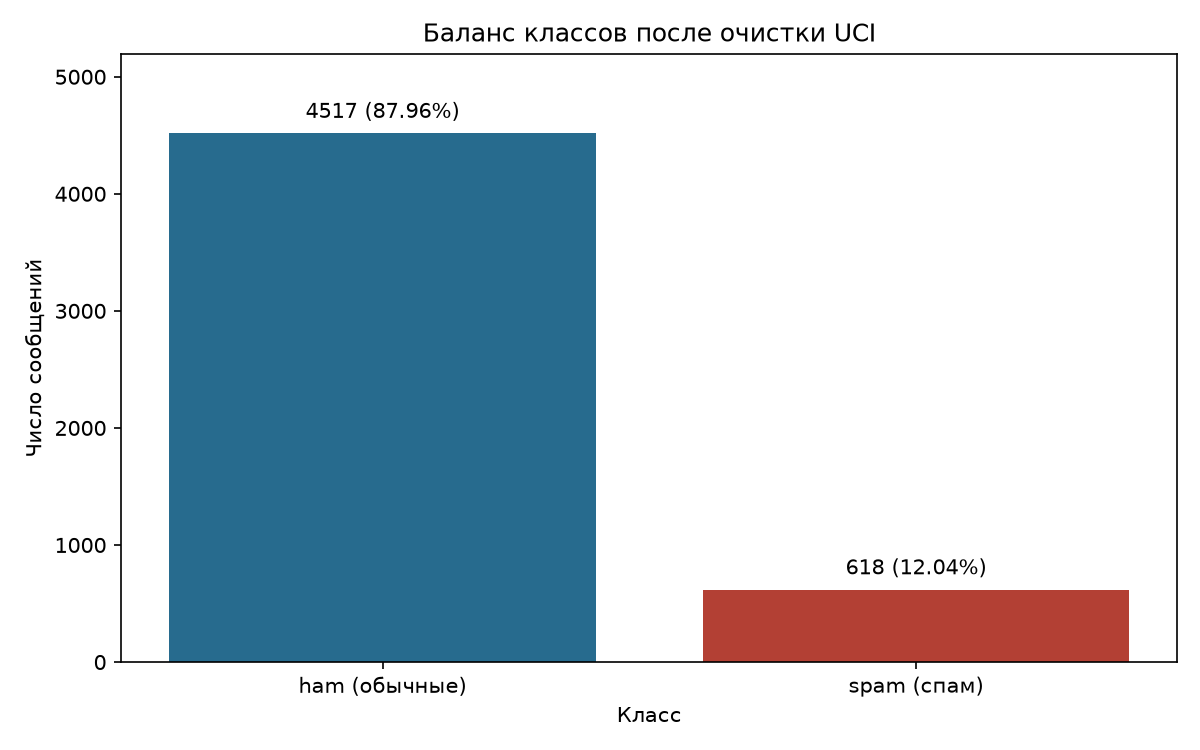

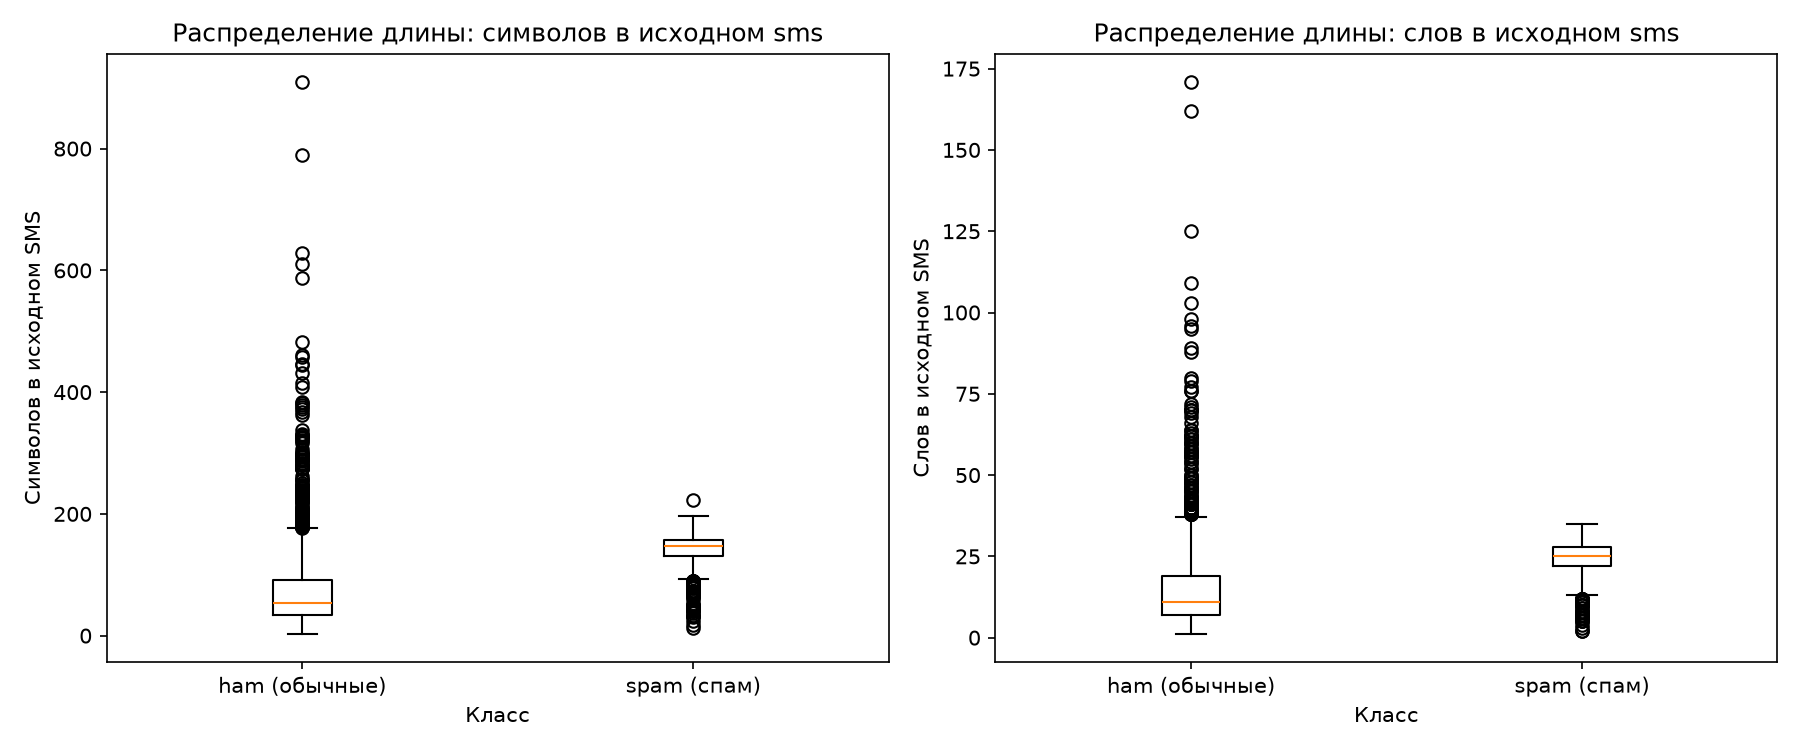

In [2]:
class_table = pd.DataFrame(summary["classes"]).T
display(
    class_table[
        [
            "count",
            "percentage",
            "mean_chars_raw",
            "median_chars_raw",
            "mean_words_raw",
            "mean_chars_clean",
            "mean_words_clean",
        ]
    ]
)
figures = plot_eda(features, summary, ROOT / "docs/figures")
for path in figures[:2]:
    display(Image(filename=str(path)))

## Топ-20 слов и биграмм каждого класса

NLTK RegexpTokenizer; локальные английские стоп-слова NLTK удаляются до формирования биграмм внутри каждого сообщения. Сущности остаются токенами. Биграммы не пересекают границы SMS. Считаются вхождения, а не число документов.

ham


,Слово / биграмма,Число
0,<num>,1067
1,u,925
2,get,301
3,gt,288
4,lt,287
5,ok,256
6,go,248
7,got,228
8,know,226
9,like,224


,Слово / биграмма,Число
0,lt gt,254
1,<num> <num>,51
2,<num> u,42
3,let know,39
4,u <num>,36
5,take care,36
6,r u,35
7,u r,33
8,wan <num>,31
9,k k,26


spam


,Слово / биграмма,Число
0,<num>,1854
1,<phone>,351
2,call,291
3,<money>,266
4,free,189
5,p,147
6,u,138
7,txt,133
8,<url>,116
9,stop,116


,Слово / биграмма,Число
0,<num> <num>,234
1,call <phone>,191
2,<num> p,144
3,box <num>,47
4,<phone> <num>,44
5,<num> ppm,38
6,<money> prize,36
7,<num> free,36
8,please call,35
9,<money> cash,34


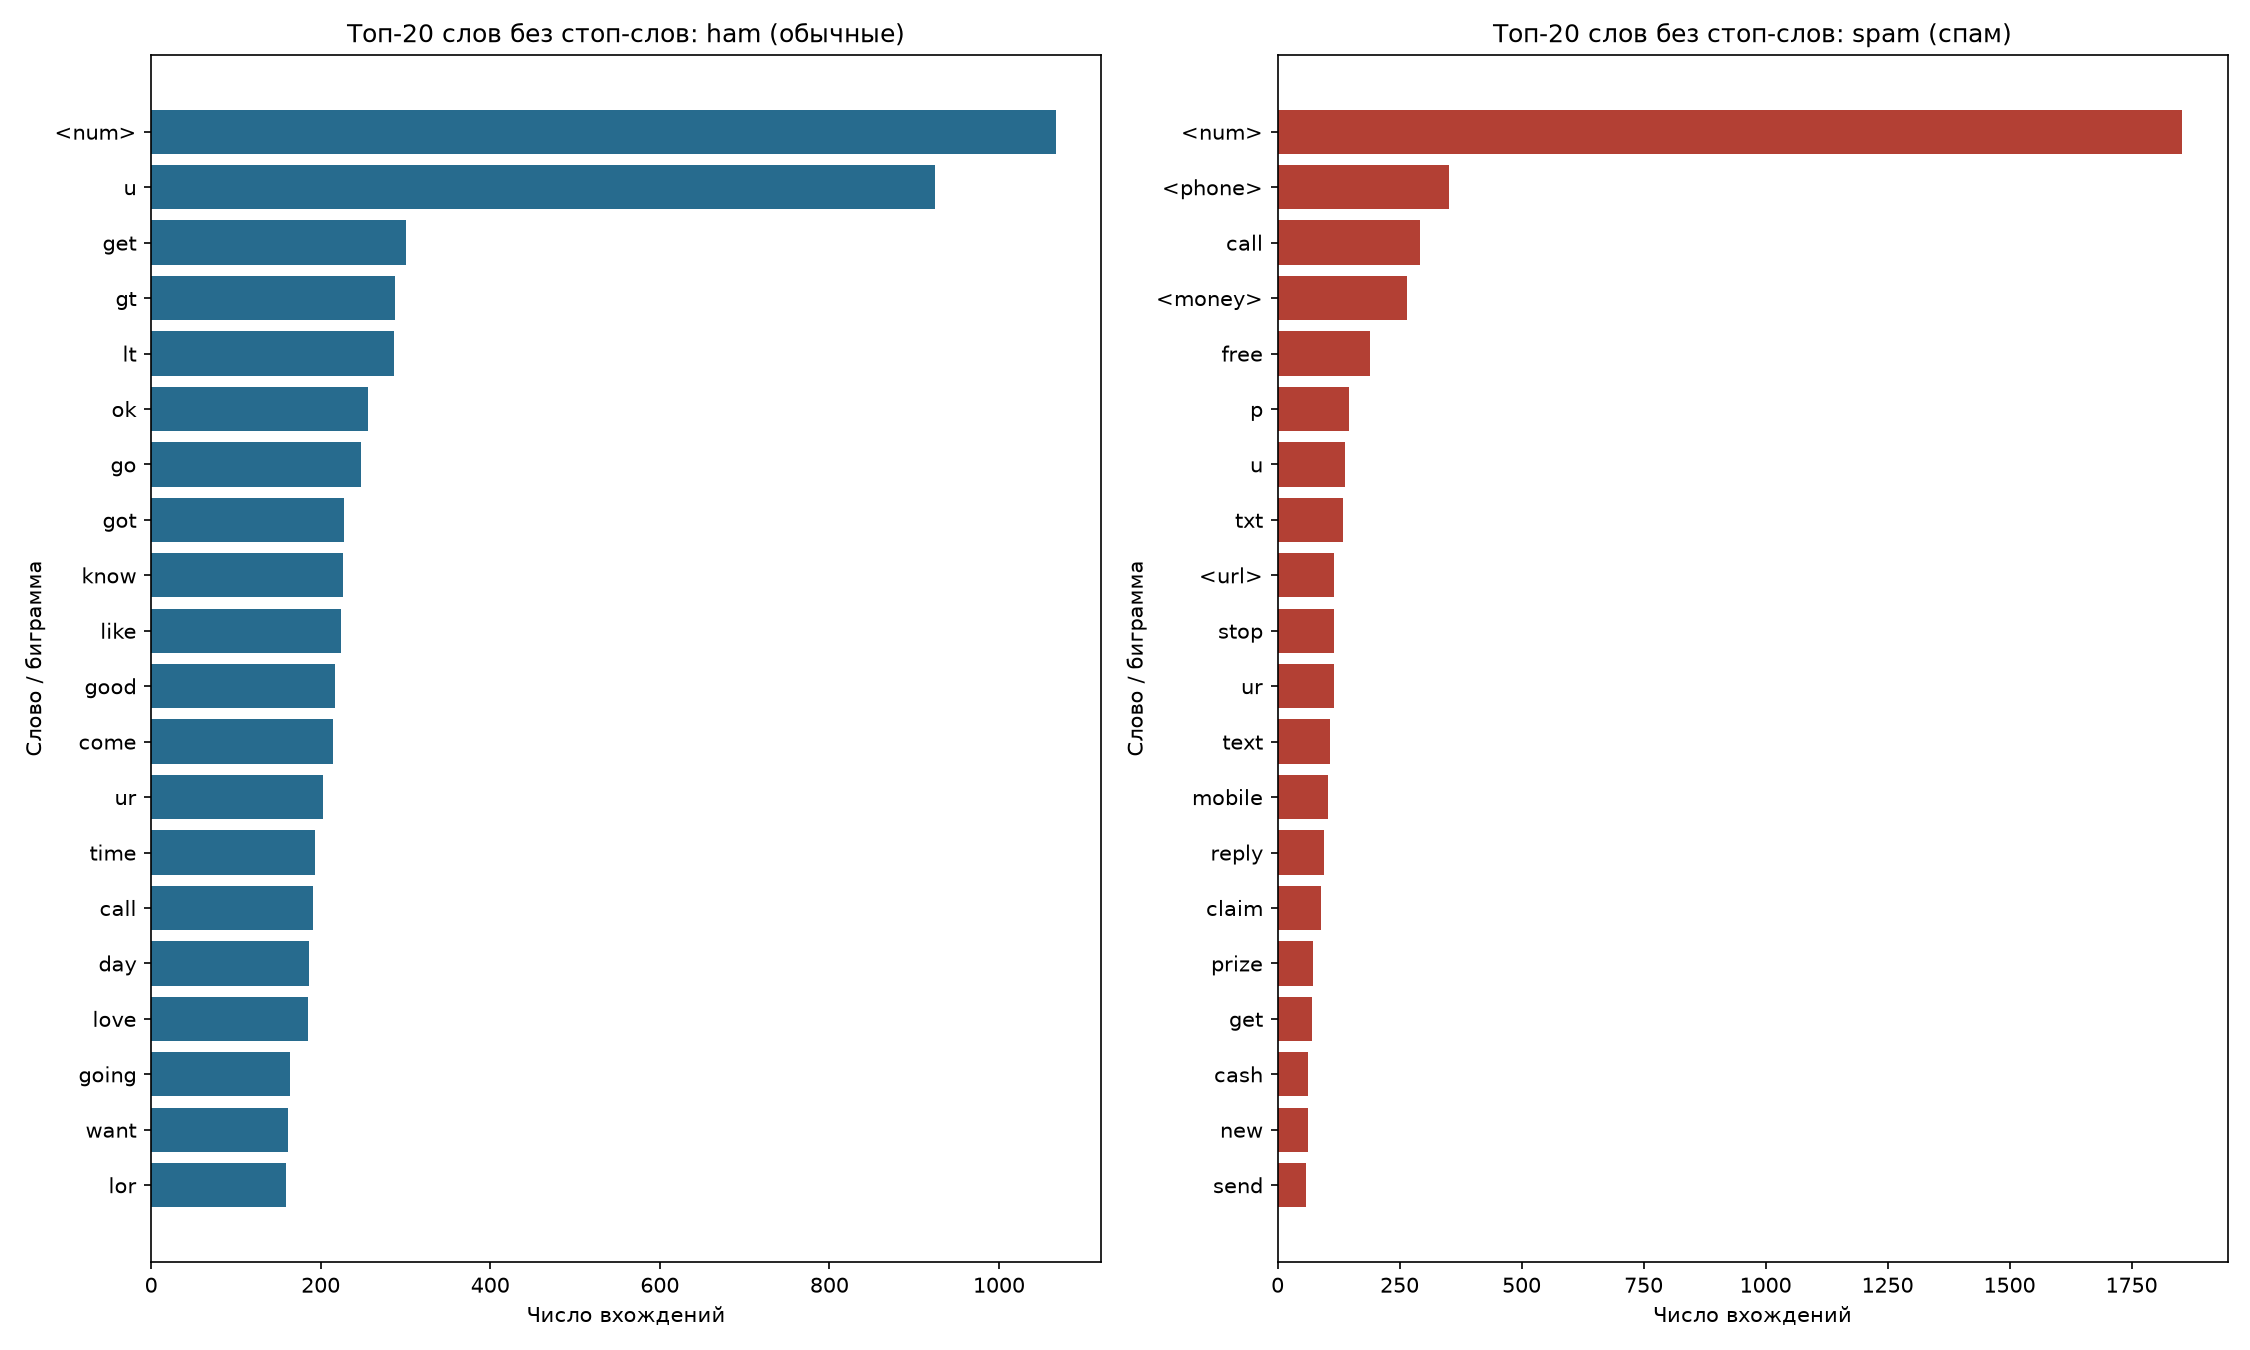

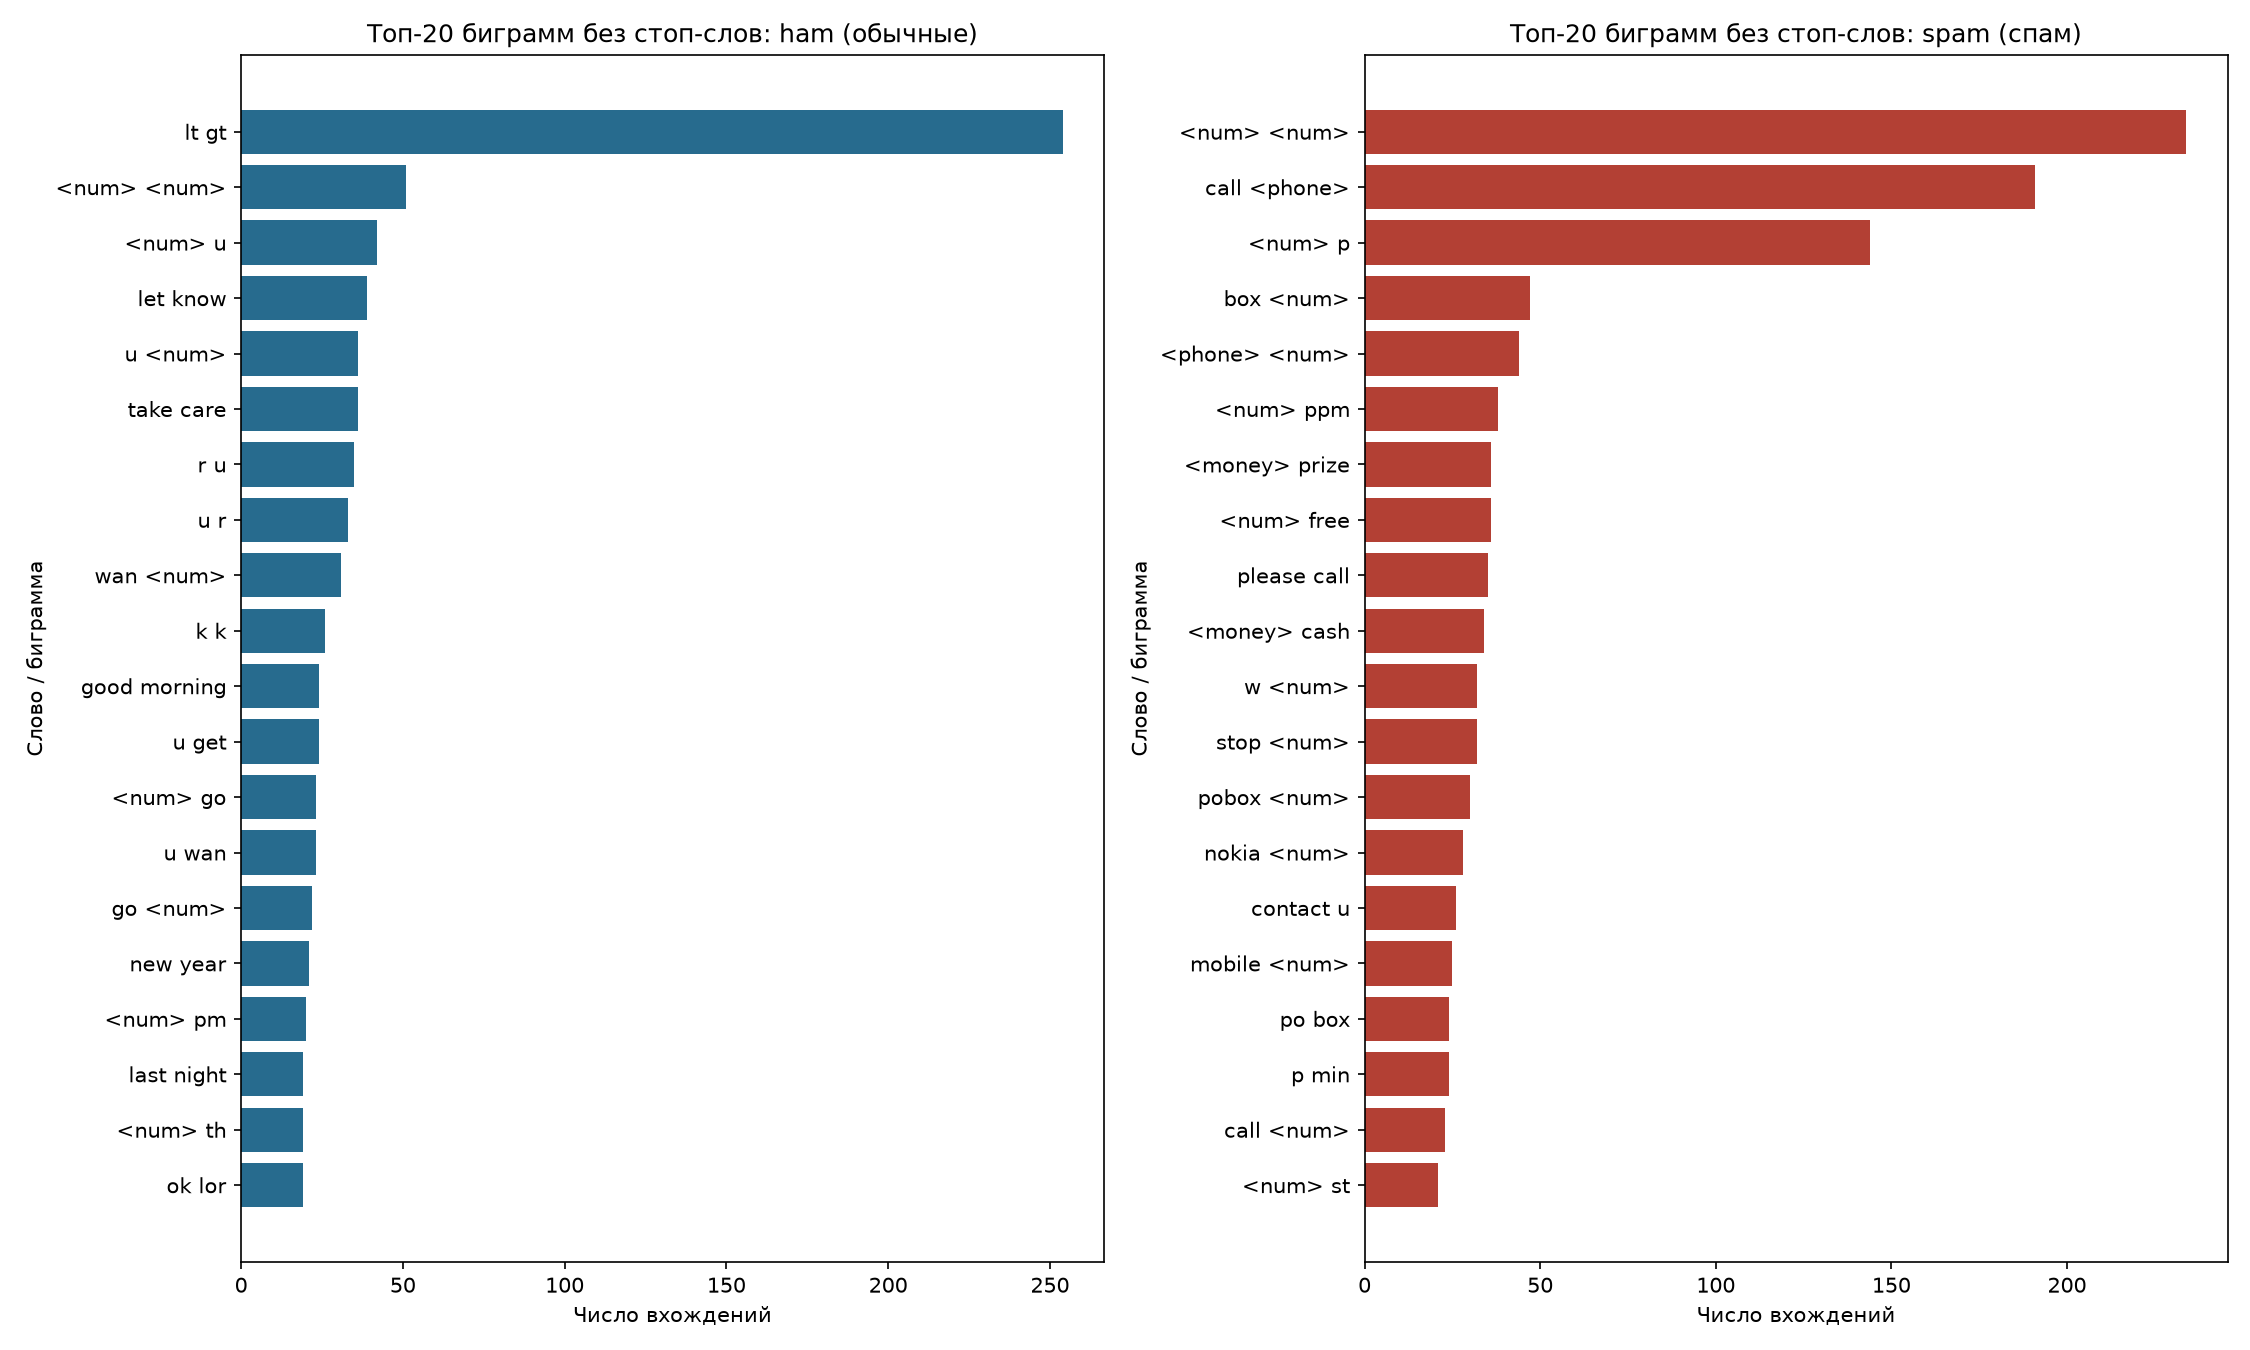

In [3]:
for label, name in [("0", "ham"), ("1", "spam")]:
    print(name)
    for key in ["top20_words", "top20_bigrams"]:
        values = summary["classes"][label][key]
        display(pd.DataFrame(values, columns=["Слово / биграмма", "Число"]))
for path in figures[2:4]:
    display(Image(filename=str(path)))

## Доли URL, телефонов, сумм и !

Доля сообщений с наличием хотя бы одного соответствующего токена/символа, отдельно по классам.

,0,1
url,0.221386,18.122977
phone,0.088554,51.779935
money,0.265663,34.304207
pressure,11.733451,47.087379


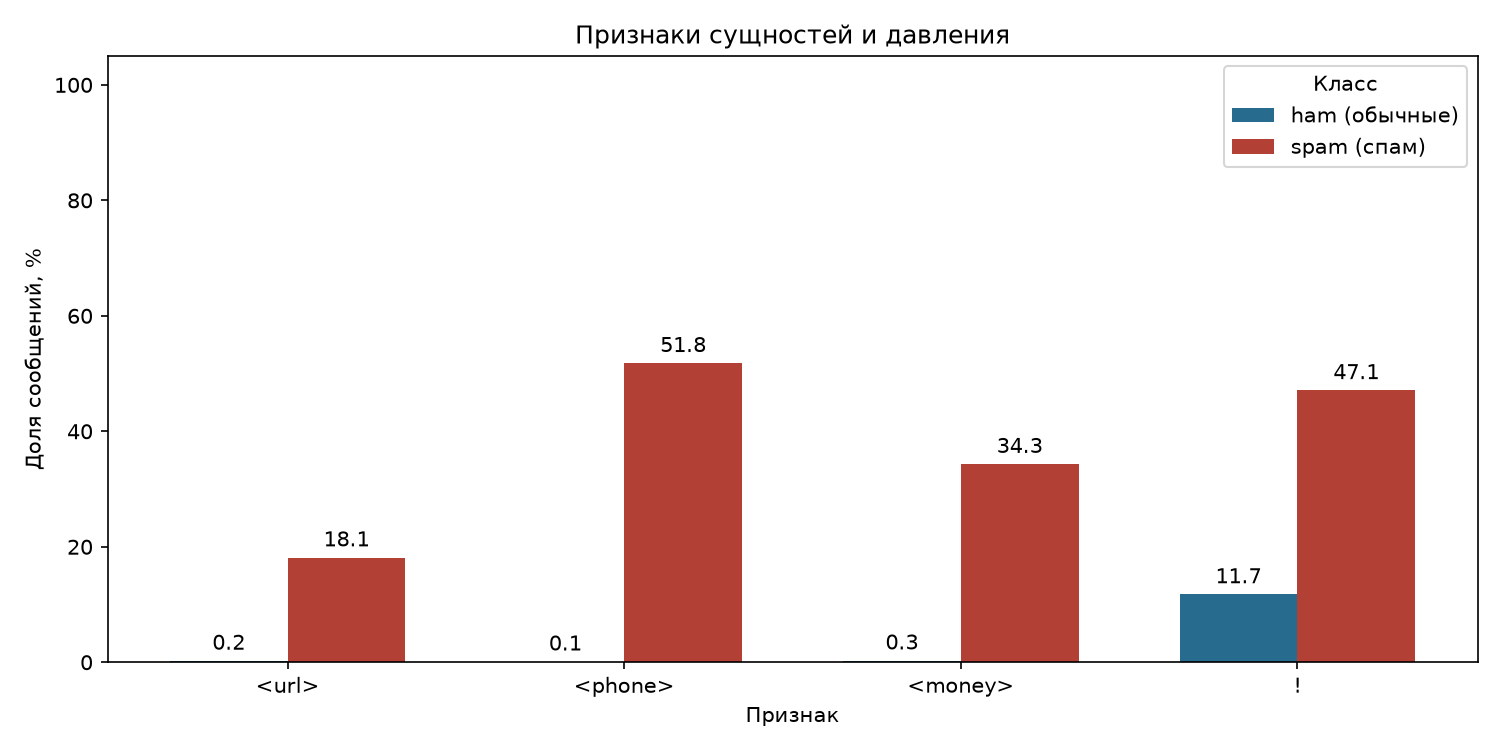

In [4]:
display(
    pd.DataFrame(
        {label: values["indicator_percentages"] for label, values in summary["classes"].items()}
    )
)
display(Image(filename=str(figures[4])))

## Наблюдения и ограничения

Все следующие числа рассчитаны выполненными ячейками.

In [5]:
facts = observations(summary)
display(Markdown(chr(10).join("- " + fact for fact in facts)))
summary["source_sha256"] = sha256(source.read_bytes())
summary["observations"] = facts
write_json(ROOT / "docs/reports/05_eda.json", summary)
report = "# Задание 5 — фактические результаты EDA" + chr(10) * 2
report += chr(10).join("- " + f for f in facts)
report += chr(10) * 2
report += "Исследован весь очищенный UCI до обучения без подбора параметров. "
report += "Русский test-only не использован. Пять PNG — docs/figures/. "
report += "Дисбаланс учитывается стратификацией; для LR планируется balanced, "
report += "далее Precision/Recall/F1/F2, а не только Accuracy. "
report += "Модель не обучена, качество не измерено." + chr(10)
(ROOT / "docs/05_eda.md").write_text(report, encoding="utf-8")

- После очистки 5135 SMS: ham=4517 (87.96%), spam=618 (12.04%).
- Средняя длина исходного текста: ham 70.90 символа, spam 137.50; медианы 53 и 148 соответственно.
- Среднее число слов: ham 14.24, spam 23.72.
- URL: ham 0.22%, spam 18.12% сообщений.
- Телефоны: ham 0.09%, spam 51.78% сообщений.
- Суммы: ham 0.27%, spam 34.30% сообщений.
- Восклицательный знак: ham 11.73%, spam 47.09% сообщений.
- Это описательные различия данного корпуса, не метрики классификатора и не причинные связи.

819

Дисбаланс требует стратификации, class_weight для LR и оценки Precision/Recall/F1/F2. Решения об алгоритме не принимаются в этом notebook. Облако слов опционально и не строилось. Наблюдения корпуса не доказывают качество на новых SMS, особенно русском языке.